# 02 — Estudio de simulación · Simulation study

**ES:** ¿Qué tan bien funciona la lógica de detección de Vigía cuando **conocemos la verdad**? En datos reales casi nunca sabemos exactamente cuándo empezó y terminó cada cierre de ojos. Acá generamos conductores sintéticos con `scripts/lib/synthetic.mjs` (cierres con rampas de apertura/cierre, bostezos, charla, cabeceos, miradas a los espejos y momentos sin rostro), los pasamos por el **mismo** `FatigueMonitor` de la app y medimos precisión, recall, errores y tiempos.

**EN:** How well does Vigía's detection logic work when **the truth is known**? Synthetic drivers go through the **same** `FatigueMonitor` used by the app, and we measure precision, recall, errors and timing.

Regenerar / regenerate: `node scripts/simulation_study.mjs` (≈ 20 s, seeds fijas / fixed seeds).

> ⚠️ Es un modelo simplificado de la realidad: sirve para entender **comportamientos y trade-offs** del algoritmo, no para afirmar su exactitud en personas reales.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vigia_analysis.study import load_study, detection_metrics, auc, roc_curve, bootstrap_ci, alarm_delay

IMG = Path("../../docs/img"); IMG.mkdir(parents=True, exist_ok=True)
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "magenta": "#e87ba4",
     "ink": "#0b0b0b", "muted": "#52514e", "grid": "#e5e4e0"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": C["grid"], "axes.edgecolor": C["muted"],
                     "axes.labelcolor": C["ink"], "xtick.color": C["muted"], "ytick.color": C["muted"],
                     "font.size": 10})
S = load_study()
summary = {}
{k: v.shape for k, v in S.items()}

{'e1': (192, 23),
 'e2': (60, 22),
 'e3': (24, 22),
 'e4': (900, 10),
 'drivers': (30, 5)}

## E1 — Umbral de "ojo cerrado" × ruido · Closed-eye threshold × noise

El ojo cuenta como cerrado cuando `EAR < r × EAR_base`. Barrimos `r` de 0,50 a 0,85 con el ruido normal del sensor (×1) y con el doble (×2).

In [2]:
m1 = detection_metrics(S["e1"], ["noise_scale", "ratio"]).reset_index()
cols = ["noise_scale", "ratio", "blink_recall", "blink_precision", "blink_f1", "long_recall", "long_fp_per_h", "perclos_bias"]
m1[cols].round(3)

,noise_scale,ratio,blink_recall,blink_precision,blink_f1,long_recall,long_fp_per_h,perclos_bias
0,1,0.50,0.968,0.998,0.983,0.958,0.0,0.005
1,1,0.55,0.989,0.998,0.993,0.958,0.0,0.008
2,1,0.60,0.997,0.998,0.997,0.958,0.0,0.010
3,1,0.65,1.000,0.998,0.999,0.958,0.0,0.012
4,1,0.70,1.000,0.998,0.999,0.972,0.0,0.014
5,1,0.75,1.000,0.998,0.999,0.986,0.0,0.017
6,1,0.80,1.000,0.992,0.996,1.000,0.0,0.020
7,1,0.85,1.000,0.923,0.960,1.000,0.0,0.029
8,2,0.50,0.960,0.996,0.978,0.944,0.0,0.005
9,2,0.55,0.984,0.997,0.991,0.958,0.0,0.008


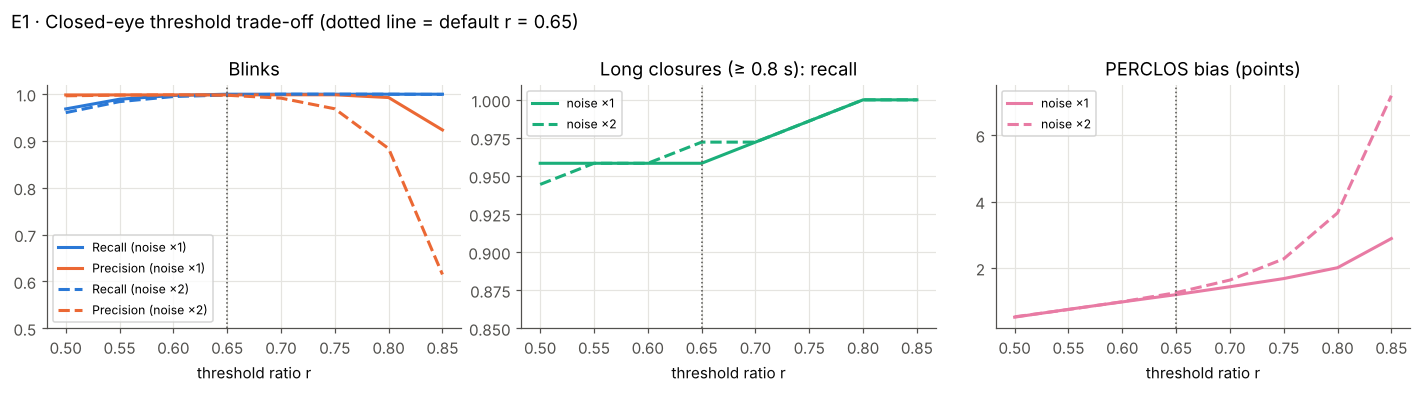

{'default_blink_recall': 1.0,
 'default_blink_precision': 0.998,
 'default_long_recall': 0.958,
 'default_perclos_bias_pts': 1.2,
 'r085_noise2_blink_precision': 0.615,
 'r050_blink_recall': 0.968,
 'best_r_by_blink_f1_noise2': 0.65}

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
styles = {1: "-", 2: "--"}
for ns, g in m1.groupby("noise_scale"):
    axes[0].plot(g.ratio, g.blink_recall, styles[ns], color=C["blue"], lw=2, label=f"Recall (noise ×{ns})")
    axes[0].plot(g.ratio, g.blink_precision, styles[ns], color=C["orange"], lw=2, label=f"Precision (noise ×{ns})")
    axes[1].plot(g.ratio, g.long_recall, styles[ns], color=C["aqua"], lw=2, label=f"noise ×{ns}")
    axes[2].plot(g.ratio, 100 * g.perclos_bias, styles[ns], color=C["magenta"], lw=2, label=f"noise ×{ns}")
for ax in axes: ax.axvline(0.65, color=C["muted"], lw=1, ls=":"); ax.set_xlabel("threshold ratio r")
axes[0].set_title("Blinks"); axes[0].set_ylim(0.5, 1.02); axes[0].legend(fontsize=8)
axes[1].set_title("Long closures (≥ 0.8 s): recall"); axes[1].set_ylim(0.85, 1.01); axes[1].legend(fontsize=8)
axes[2].set_title("PERCLOS bias (points)"); axes[2].legend(fontsize=8)
fig.suptitle("E1 · Closed-eye threshold trade-off (dotted line = default r = 0.65)", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(IMG / "study_threshold.png", bbox_inches="tight"); plt.show()

d = m1.set_index(["noise_scale", "ratio"])
summary["e1"] = {
    "default_blink_recall": round(float(d.loc[(1, 0.65), "blink_recall"]), 3),
    "default_blink_precision": round(float(d.loc[(1, 0.65), "blink_precision"]), 3),
    "default_long_recall": round(float(d.loc[(1, 0.65), "long_recall"]), 3),
    "default_perclos_bias_pts": round(100 * float(d.loc[(1, 0.65), "perclos_bias"]), 2),
    "r085_noise2_blink_precision": round(float(d.loc[(2, 0.85), "blink_precision"]), 3),
    "r050_blink_recall": round(float(d.loc[(1, 0.5), "blink_recall"]), 3),
    "best_r_by_blink_f1_noise2": float(m1[m1.noise_scale == 2].sort_values("blink_f1").ratio.iloc[-1]),
}
summary["e1"]

**Lectura:** un umbral bajo (r = 0,50) pierde parpadeos cortos; uno alto (r = 0,85) con ruido doble inventa parpadeos (la precisión cae fuerte) e infla el PERCLOS. El valor por defecto r = 0,65 queda en la zona estable con ambos niveles de ruido. Los cierres largos que se escapan están justo en el borde de 0,8 s: las rampas de cierre/apertura "recortan" la duración medida.

**Reading:** a low threshold misses short blinks; a high one with double noise invents blinks and inflates PERCLOS. The default r = 0.65 sits in the stable zone for both noise levels. Missed long closures sit right at the 0.8 s boundary: eyelid ramps shorten the measured duration.

## E2 — Cuadros por segundo · Frame rate

El motor clásico Haar corre a ~15 cuadros/s y un celular lento puede bajar a 5–10.

In [4]:
m2 = detection_metrics(S["e2"], ["fps"]).reset_index()
m2[["fps", "blink_recall", "blink_precision", "long_recall", "crit_recall", "crit_latency_ms", "perclos_mae"]].round(3)

,fps,blink_recall,blink_precision,long_recall,crit_recall,crit_latency_ms,perclos_mae
0,5,0.596,0.999,1.000,1.0,1694.366,0.013
1,10,0.943,0.998,1.000,1.0,1564.196,0.012
2,15,1.000,0.998,0.958,1.0,1595.444,0.012
3,20,1.000,0.998,0.986,1.0,1547.825,0.012
4,30,1.000,0.998,0.958,1.0,1567.666,0.012


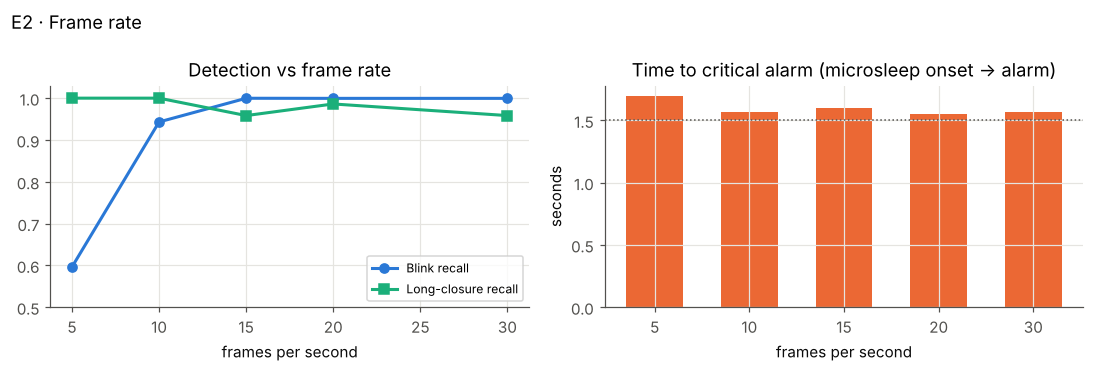

{'blink_recall_5fps': 0.596,
 'blink_recall_10fps': 0.943,
 'blink_recall_15fps': 1.0,
 'blink_recall_30fps': 1.0,
 'crit_latency_s_5fps': 1.69,
 'crit_latency_s_15fps': 1.6,
 'crit_latency_s_30fps': 1.57}

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(m2.fps, m2.blink_recall, "o-", color=C["blue"], lw=2, ms=6, label="Blink recall")
axes[0].plot(m2.fps, m2.long_recall, "s-", color=C["aqua"], lw=2, ms=6, label="Long-closure recall")
axes[0].set_ylim(0.5, 1.03); axes[0].set_xlabel("frames per second"); axes[0].set_title("Detection vs frame rate"); axes[0].legend(fontsize=8)
axes[1].bar(m2.fps.astype(str), m2.crit_latency_ms / 1000, color=C["orange"], width=0.6)
axes[1].axhline(1.5, color=C["muted"], ls=":", lw=1)
axes[1].set_ylabel("seconds"); axes[1].set_xlabel("frames per second"); axes[1].set_title("Time to critical alarm (microsleep onset → alarm)")
fig.suptitle("E2 · Frame rate", x=0.01, ha="left"); fig.tight_layout(); fig.savefig(IMG / "study_fps.png", bbox_inches="tight"); plt.show()
d2 = m2.set_index("fps")
summary["e2"] = {f"blink_recall_{f}fps": round(float(d2.loc[f, "blink_recall"]), 3) for f in [5, 10, 15, 30]}
summary["e2"].update({f"crit_latency_s_{f}fps": round(float(d2.loc[f, "crit_latency_ms"]) / 1000, 2) for f in [5, 15, 30]})
summary["e2"]

**Lectura:** desde 15 cuadros/s no se pierden parpadeos; a 5 cuadros/s se pierde ~40 % (un parpadeo de 150 ms puede caer entre dos cuadros). La alarma de microsueño llega ~1,5–1,7 s después de cerrar los ojos en todas las velocidades: está dominada por la regla de 1,5 s, no por la cámara.

**Reading:** from 15 fps on, no blinks are lost; at 5 fps ~40 % are (a 150 ms blink can fall between frames). The microsleep alarm fires ~1.5–1.7 s after eye closure at every rate: the 1.5 s rule dominates, not the camera.

## E3 — Calibración personal vs. umbral fijo · Personal calibration vs fixed threshold

12 conductores con ojos de distinta forma (EAR abierto de 0,22 a 0,34).

In [6]:
e3 = S["e3"].copy()
e3["blink_fp_per_h"] = e3.blink_fp / e3.hours
pivot = e3.pivot_table(index="base_ear", columns="method", values=["blink_fp_per_h", "perclos_bias"]).round(3)
pivot

blink_fp_per_h          perclos_bias         
method       fixed_0.20 personal   fixed_0.20 personal
base_ear                                              
0.22000         183.002      0.0        0.049    0.008
0.23091        1305.013      0.0        0.087    0.010
0.24182           0.000      0.0        0.012    0.007
0.25273           6.000      6.0        0.012    0.008
0.26364           0.000      0.0        0.017    0.011
0.27455           0.000      0.0        0.014    0.011
0.28545           3.000      3.0        0.009    0.008
0.29636           0.000      0.0        0.010    0.009
0.30727           6.000      6.0        0.009    0.009
0.31818           3.000      3.0        0.013    0.014
0.32909           3.000      3.0        0.010    0.012
0.34000           0.000      0.0        0.008    0.011

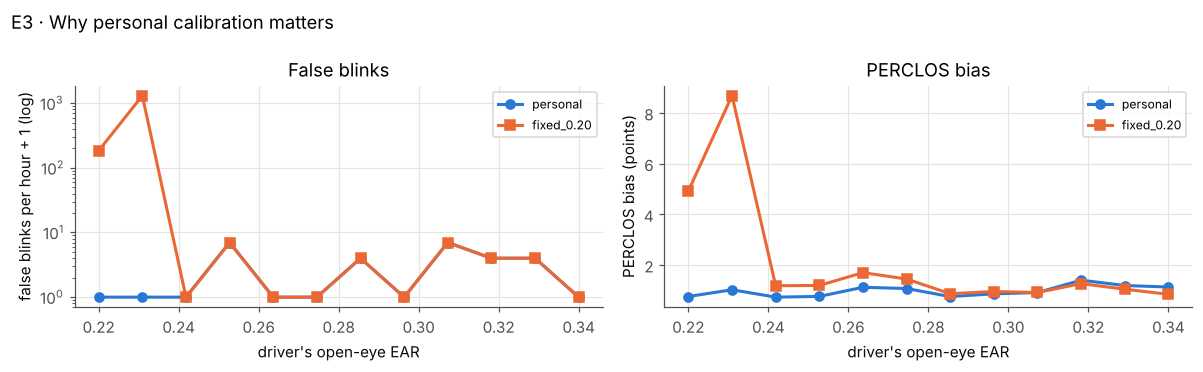

{'small_eyes_false_blinks_per_h_fixed': 744.0,
 'small_eyes_false_blinks_per_h_personal': 0.0,
 'small_eyes_perclos_bias_pts_fixed': 6.8,
 'small_eyes_perclos_bias_pts_personal': 0.9}

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for method, color, marker in [("personal", C["blue"], "o"), ("fixed_0.20", C["orange"], "s")]:
    g = e3[e3.method == method]
    axes[0].plot(g.base_ear, g.blink_fp_per_h + 1, marker + "-", color=color, lw=2, ms=6, label=method)
    axes[1].plot(g.base_ear, 100 * g.perclos_bias, marker + "-", color=color, lw=2, ms=6, label=method)
axes[0].set_yscale("log"); axes[0].set_ylabel("false blinks per hour + 1 (log)"); axes[0].set_title("False blinks")
axes[1].set_ylabel("PERCLOS bias (points)"); axes[1].set_title("PERCLOS bias")
for ax in axes: ax.set_xlabel("driver's open-eye EAR"); ax.legend(fontsize=8)
fig.suptitle("E3 · Why personal calibration matters", x=0.01, ha="left"); fig.tight_layout(); fig.savefig(IMG / "study_calibration.png", bbox_inches="tight"); plt.show()
small = e3[e3.base_ear < 0.235]
summary["e3"] = {
    "small_eyes_false_blinks_per_h_fixed": round(float(small[small.method == "fixed_0.20"].blink_fp_per_h.mean()), 0),
    "small_eyes_false_blinks_per_h_personal": round(float(small[small.method == "personal"].blink_fp_per_h.mean()), 1),
    "small_eyes_perclos_bias_pts_fixed": round(100 * float(small[small.method == "fixed_0.20"].perclos_bias.mean()), 1),
    "small_eyes_perclos_bias_pts_personal": round(100 * float(small[small.method == "personal"].perclos_bias.mean()), 1),
}
summary["e3"]

**Lectura:** con un umbral fijo (0,20), las personas de ojos más rasgados (EAR abierto ≈ 0,22) generan cientos de falsos parpadeos por hora y un PERCLOS inflado varios puntos: la app las vería "cansadas" todo el tiempo. Con calibración personal el error desaparece. Es un problema de **equidad**: el mismo umbral no sirve para todas las caras.

**Reading:** with a fixed 0.20 threshold, people with narrower eyes (open EAR ≈ 0.22) get hundreds of false blinks per hour and an inflated PERCLOS: the app would see them as "tired" all the time. Personal calibration removes the error. It is a **fairness** issue: one threshold does not fit every face.

## E4 — ¿El índice refleja la fatiga? · Does the score track fatigue?

30 conductores × 30 min. Cada minuto se etiqueta como **somnoliento** si la fatiga latente media es ≥ 0,5 (la etiqueta que en la vida real daría la escala KSS o el test PVT).

In [8]:
e4 = S["e4"].copy()
e4["drowsy"] = (e4.f_mean >= 0.5).astype(int)
features = {"score_mean": "Fatigue score (v0.1)", "perclos": "PERCLOS only", "avg_blink_ms": "Blink duration only",
            "long_closures": "Long closures only", "yawns": "Yawns only"}
rows = []
for col, label in features.items():
    point, lo, hi = bootstrap_ci(e4, lambda df, c=col: auc(df.drowsy, df[c]), n=500)
    rows.append({"feature": label, "auc": point, "ci_low": lo, "ci_high": hi})
auc_table = pd.DataFrame(rows).round(3)
print(f"minutes: {len(e4)}, drowsy share: {e4.drowsy.mean():.1%}")
auc_table

minutes: 900, drowsy share: 24.2%


,feature,auc,ci_low,ci_high
0,Fatigue score (v0.1),0.978,0.962,0.988
1,PERCLOS only,0.966,0.953,0.978
2,Blink duration only,0.995,0.991,0.998
3,Long closures only,0.745,0.700,0.785
4,Yawns only,0.604,0.572,0.637


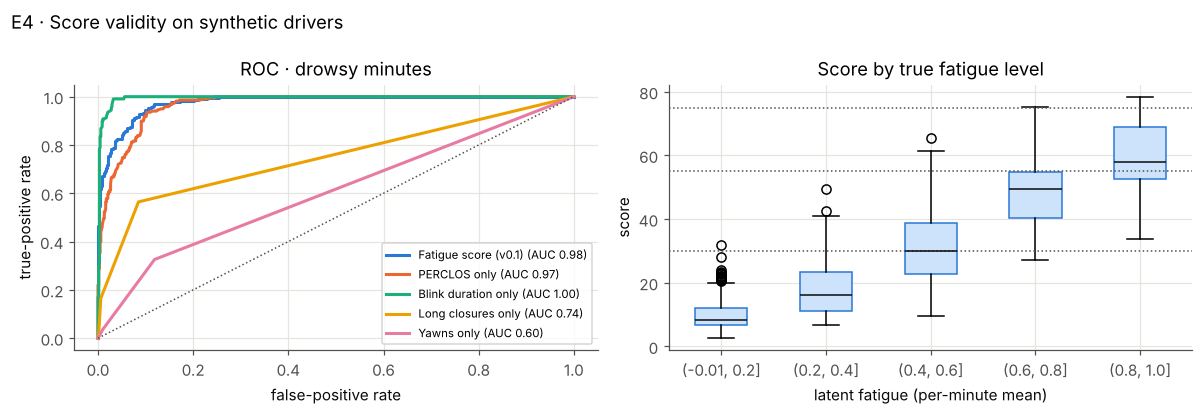

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (col, label), color in zip(features.items(), [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"]]):
    fpr, tpr, _ = roc_curve(e4.drowsy, e4[col])
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC {auc(e4.drowsy, e4[col]):.2f})")
axes[0].plot([0, 1], [0, 1], color=C["muted"], ls=":", lw=1)
axes[0].set_xlabel("false-positive rate"); axes[0].set_ylabel("true-positive rate"); axes[0].set_title("ROC · drowsy minutes"); axes[0].legend(fontsize=7.5, loc="lower right")
bins = pd.cut(e4.f_mean, [-0.01, 0.2, 0.4, 0.6, 0.8, 1.0])
data = [g.score_mean.values for _, g in e4.groupby(bins, observed=False)]
axes[1].boxplot(data, tick_labels=[str(b) for b in bins.cat.categories], patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", color=C["blue"]), medianprops=dict(color=C["ink"]))
for y in (30, 55, 75): axes[1].axhline(y, color=C["muted"], ls=":", lw=1)
axes[1].set_xlabel("latent fatigue (per-minute mean)"); axes[1].set_ylabel("score"); axes[1].set_title("Score by true fatigue level")
fig.suptitle("E4 · Score validity on synthetic drivers", x=0.01, ha="left"); fig.tight_layout(); fig.savefig(IMG / "study_score.png", bbox_inches="tight"); plt.show()

In [10]:
# Umbral de alerta "moderada" (índice ≥ 55) como clasificador · "moderate" alert threshold as a classifier
pred = (e4.score_mean >= 55).astype(int)
tp = int(((pred == 1) & (e4.drowsy == 1)).sum()); fp = int(((pred == 1) & (e4.drowsy == 0)).sum())
fn = int(((pred == 0) & (e4.drowsy == 1)).sum()); tn = int(((pred == 0) & (e4.drowsy == 0)).sum())
prec, rec = tp / (tp + fp), tp / (tp + fn)
fpr_alert = fp / (fp + tn)
delays = alarm_delay(e4)
drowsy_drivers = delays[delays.drowsy]
summary["e4"] = {
    "minutes": int(len(e4)), "drowsy_share": round(float(e4.drowsy.mean()), 3),
    "auc": auc_table.set_index("feature")["auc"].to_dict(),
    "auc_ci_score": [float(auc_table.iloc[0].ci_low), float(auc_table.iloc[0].ci_high)],
    "moderate_threshold": {"precision": round(prec, 3), "recall": round(rec, 3), "false_positive_rate": round(fpr_alert, 3),
                           "tp": tp, "fp": fp, "fn": fn, "tn": tn},
    "alarm_delay_min_median": float(drowsy_drivers.delay_min.median()),
    "alarm_delay_min_iqr": [float(drowsy_drivers.delay_min.quantile(0.25)), float(drowsy_drivers.delay_min.quantile(0.75))],
    "drowsy_drivers": int(drowsy_drivers.shape[0]),
    "drowsy_drivers_never_alarmed": int(drowsy_drivers.alarm_min.isna().sum()),
    "alert_drivers_with_false_alarm": int(delays[~delays.drowsy].alarm_min.notna().sum()),
    "alert_drivers": int((~delays.drowsy).sum()),
}
summary["e4"]

{'minutes': 900,
 'drowsy_share': 0.242,
 'auc': {'Fatigue score (v0.1)': 0.978,
  'PERCLOS only': 0.966,
  'Blink duration only': 0.995,
  'Long closures only': 0.745,
  'Yawns only': 0.604},
 'auc_ci_score': [0.962, 0.988],
 'moderate_threshold': {'precision': 1.0,
  'recall': 0.284,
  'false_positive_rate': 0.0,
  'tp': 62,
  'fp': 0,
  'fn': 156,
  'tn': 682},
 'alarm_delay_min_median': 2.0,
 'alarm_delay_min_iqr': [1.0, 5.0],
 'drowsy_drivers': 22,
 'drowsy_drivers_never_alarmed': 1,
 'alert_drivers_with_false_alarm': 1,
 'alert_drivers': 8}

In [11]:
# Umbral que maximiza el índice de Youden (TPR − FPR) · Threshold maximising Youden's J
fpr, tpr, thr = roc_curve(e4.drowsy, e4.score_mean)
j = tpr - fpr; k = int(np.argmax(j))
best = float(thr[k])
p2 = (e4.score_mean >= best).astype(int)
tp2 = int(((p2 == 1) & (e4.drowsy == 1)).sum()); fp2 = int(((p2 == 1) & (e4.drowsy == 0)).sum()); fn2 = int(((p2 == 0) & (e4.drowsy == 1)).sum())
summary["e4"]["youden"] = {"threshold": round(best, 1), "tpr": round(float(tpr[k]), 3), "fpr": round(float(fpr[k]), 3),
                           "precision": round(tp2 / (tp2 + fp2), 3), "recall": round(tp2 / (tp2 + fn2), 3)}
summary["e4"]["youden"]

{'threshold': 23.2,
 'tpr': 0.968,
 'fpr': 0.117,
 'precision': 0.725,
 'recall': 0.968}

**Calibración del umbral:** el índice **ordena** muy bien los minutos (AUC alta), pero el corte "moderada" (55) es **conservador**: casi no da falsas alarmas, aunque deja pasar muchos minutos somnolientos tempranos. El umbral óptimo de Youden queda bastante más abajo. Conclusión de ciencia de datos: los cortes de nivel no deberían fijarse a mano, sino **aprenderse con etiquetas reales**, eligiendo explícitamente el balance entre alarmas perdidas y falsas alarmas.

**Threshold calibration:** the score **ranks** minutes very well (high AUC), but the "moderate" cut-off (55) is **conservative**: almost no false alarms, yet many early drowsy minutes are missed. Youden's optimal threshold is much lower. Data-science takeaway: level cut-offs should not be hand-set but **learned from real labels**, choosing the trade-off between missed and false alarms explicitly.

**Lectura honesta:** en este mundo sintético el índice separa muy bien los minutos somnolientos (AUC alta) y combina mejor que los eventos sueltos (cierres largos, bostezos). Pero la duración del parpadeo sola sale casi perfecta **porque el simulador la ata directamente a la fatiga**: es un sesgo del generador, no una virtud demostrada. Por eso el próximo paso es validar con etiquetas reales (KSS / PVT) y datasets públicos.

**Honest reading:** in this synthetic world the score separates drowsy minutes very well and beats single events. But blink duration alone looks almost perfect **because the simulator ties it directly to fatigue**: a generator bias, not a proven strength. Hence the next step: validate with real labels (KSS / PVT) and public datasets.

In [12]:
out = Path("../results/simulation/summary.json")
out.write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "e1": {
    "default_blink_recall": 1.0,
    "default_blink_precision": 0.998,
    "default_long_recall": 0.958,
    "default_perclos_bias_pts": 1.2,
    "r085_noise2_blink_precision": 0.615,
    "r050_blink_recall": 0.968,
    "best_r_by_blink_f1_noise2": 0.65
  },
  "e2": {
    "blink_recall_5fps": 0.596,
    "blink_recall_10fps": 0.943,
    "blink_recall_15fps": 1.0,
    "blink_recall_30fps": 1.0,
    "crit_latency_s_5fps": 1.69,
    "crit_latency_s_15fps": 1.6,
    "crit_latency_s_30fps": 1.57
  },
  "e3": {
    "small_eyes_false_blinks_per_h_fixed": 744.0,
    "small_eyes_false_blinks_per_h_personal": 0.0,
    "small_eyes_perclos_bias_pts_fixed": 6.8,
    "small_eyes_perclos_bias_pts_personal": 0.9
  },
  "e4": {
    "minutes": 900,
    "drowsy_share": 0.242,
    "auc": {
      "Fatigue score (v0.1)": 0.978,
      "PERCLOS only": 0.966,
      "Blink duration only": 0.995,
      "Long closures only": 0.745,
      "Yawns only": 0.604
    },
    "auc_ci_score": [
      0.962,
   